# Chapitre 3 - Cours 3 : schémas souples et langages de requête

Le cours 1 a pesé la localité, le cours 2 les jointures. Restent deux arguments du débat
entre relationnel et documents : la **souplesse du schéma** et le **langage de requête**.
Ce cours couvre la section *When to Use Which Model* (*Schema flexibility in the document
model*, *Query languages for documents*, *Convergence of document and relational
databases*) et l'encadré *Terminology: Declarative Query Languages*.

**Plan.**

1. Quel modèle simplifie le code ?
2. Schéma à la lecture, schéma à l'écriture.
3. Déclaratif contre impératif.
4. Le pipeline d'agrégation, un langage de requête pour documents.
5. La convergence des modèles.
6. Les listes réordonnables et l'indexation fractionnaire.

In [1]:
import json
import sqlite3
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Quel modèle simplifie le code ? (section *When to Use Which Model*)

Le verdict du livre tient en deux phrases :

- si les données ont une **structure de document** (un arbre de relations un-à-plusieurs,
  chargé d'un bloc), le modèle document est probablement le bon choix. Le découpage
  relationnel d'un tel arbre en plusieurs tables, le *shredding*, donne des schémas
  lourds et du code inutilement compliqué (cours 1) ;
- si l'application a besoin de relations **plusieurs-à-plusieurs**, le modèle document
  perd son attrait : jointures émulées dans le code, dénormalisation à maintenir
  (cours 2). Et si ces relations dominent, le **graphe** devient le modèle naturel
  (cours 4).

Le modèle document a une autre limite, plus discrète : on ne peut pas désigner
**directement** un élément imbriqué. Il faut dire « le deuxième poste du profil 42 »,
une adresse **positionnelle** qui devient fausse dès que la liste change. En relationnel,
chaque poste a son propre identifiant stable. Démonstration : un autre service a retenu
l'adresse d'un poste pour y attacher une recommandation, puis l'utilisateur supprime un
ancien poste.

In [2]:
doc = {"user_id": 42, "positions": [
    {"job_title": "Architecte de données", "organization": "Datanet"},
    {"job_title": "Ingénieure logiciel", "organization": "Novasoft"},
    {"job_title": "Stagiaire", "organization": "Pixelsoft"}]}
rel = pd.DataFrame({"id": [9001, 9002, 9003], "user_id": 42,
                    "job_title": [p["job_title"] for p in doc["positions"]]})
adresse_doc = ("profil 42", "positions", 1)           # « le 2e poste du profil 42 »
adresse_rel = 9002                                    # l'identifiant du poste

del doc["positions"][0]                               # l'utilisateur supprime son poste le plus récent
rel = rel[rel.id != 9001]
pd.DataFrame({
    "référence": ["positions[1] dans le document", "positions.id = 9002"],
    "désignait": ["Ingénieure logiciel", "Ingénieure logiciel"],
    "désigne maintenant": [doc["positions"][adresse_doc[2]]["job_title"],
                           rel.loc[rel.id == adresse_rel, "job_title"].item()],
})

,référence,désignait,désigne maintenant
0,positions[1] dans le document,Ingénieure logiciel,Stagiaire
1,positions.id = 9002,Ingénieure logiciel,Ingénieure logiciel


La référence positionnelle pointe désormais sur le **mauvais** poste, sans aucune erreur.
Le remède est d'attribuer un identifiant à chaque élément imbriqué, ce qui revient à
réintroduire une idée relationnelle dans le document.

> **À retenir.** Arbre lu d'un bloc : modèle document. Relations plusieurs-à-plusieurs :
> relationnel, ou graphe si elles dominent. Un élément imbriqué dans un document n'a pas
> d'adresse stable sans identifiant propre.

## 2. Schéma à la lecture, schéma à l'écriture (section *Schema flexibility in the document model*)

Les bases documents, et le support JSON des bases relationnelles, n'imposent en général
**aucun schéma** : on peut ajouter n'importe quelle clé à un document, et le lecteur n'a
aucune garantie sur les champs présents. On les dit *schemaless*, ce qui est trompeur :
le code qui lit les données suppose bien une structure. Il existe un schéma **implicite**,
que la base ne vérifie pas. Le livre préfère parler de :

- **schéma à la lecture** (*schema-on-read*) : la structure est interprétée au moment
  où l'on lit, comme le typage **dynamique** d'un langage ;
- **schéma à l'écriture** (*schema-on-write*) : la base vérifie à chaque écriture que
  les données respectent le schéma déclaré, comme le typage **statique**.

La différence saute aux yeux quand le format change. Exemple du livre : on stockait le
nom complet dans un seul champ `name`, on veut désormais un champ `first_name` séparé.

**Schéma à l'écriture** : on migre la table. Ajouter une colonne avec une valeur par
défaut `NULL` est quasi instantané dans la plupart des bases ; mais remplir la colonne
(`UPDATE`) réécrit **chaque ligne**. Mesurons les deux étapes sur SQLite pour des tables
de taille croissante.

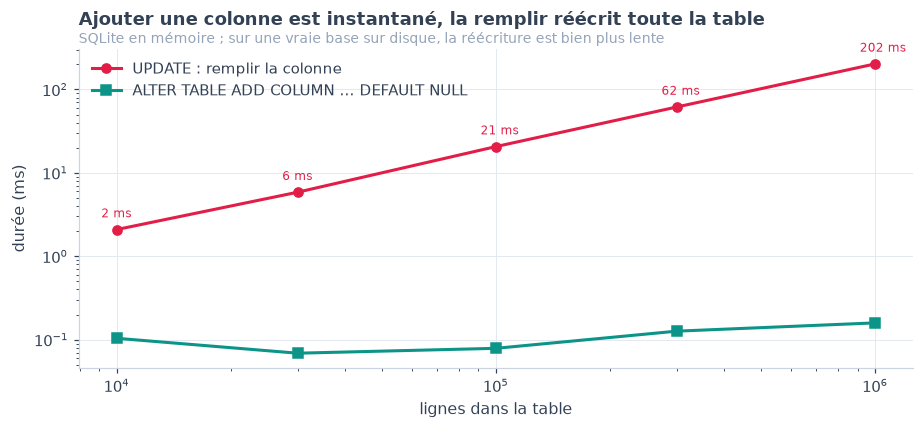

,lignes,ALTER (ms),UPDATE (ms)
0,10000,0.10,2.09
1,30000,0.07,5.86
2,100000,0.08,20.64
3,300000,0.13,61.59
4,1000000,0.16,202.29


In [3]:
def migration_cost(n):
    c = sqlite3.connect(":memory:")
    c.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, name TEXT, bio TEXT)")
    c.executemany("INSERT INTO users VALUES (?, ?, ?)",
                  ((i, f"Prénom{i % 997} Nom{i}", "x" * 60) for i in range(n)))
    c.commit()
    t0 = time.perf_counter()
    c.execute("ALTER TABLE users ADD COLUMN first_name TEXT DEFAULT NULL")
    t_alter = time.perf_counter() - t0
    t0 = time.perf_counter()
    c.execute("UPDATE users SET first_name = substr(name, 1, instr(name, ' ') - 1)")
    c.commit()
    t_update = time.perf_counter() - t0
    assert c.execute("SELECT first_name FROM users WHERE id = 5").fetchone()[0] == "Prénom5"
    return t_alter * 1e3, t_update * 1e3

tailles = [10_000, 30_000, 100_000, 300_000, 1_000_000]
mig = pd.DataFrame([(n, *migration_cost(n)) for n in tailles], columns=["lignes", "ALTER (ms)", "UPDATE (ms)"])

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.loglog(mig["lignes"], mig["UPDATE (ms)"], marker="o", color=ROSE, label="UPDATE : remplir la colonne")
ax.loglog(mig["lignes"], mig["ALTER (ms)"], marker="s", color=TEAL, label="ALTER TABLE ADD COLUMN ... DEFAULT NULL")
for x, y in zip(mig["lignes"], mig["UPDATE (ms)"]):
    ax.annotate(f"{y:.0f} ms", (x, y), (-10, 8), textcoords="offset points", fontsize=8, color=ROSE)
ax.set_xlabel("lignes dans la table"); ax.set_ylabel("durée (ms)")
ax.set_title("Ajouter une colonne est instantané, la remplir réécrit toute la table")
subtitle(ax, "SQLite en mémoire ; sur une vraie base sur disque, la réécriture est bien plus lente")
ax.legend(); plt.tight_layout(); plt.show()
mig.round(2)

L'`ALTER TABLE` reste sous la milliseconde quelle que soit la taille (SQLite ne fait que
modifier le schéma enregistré), tandis que l'`UPDATE` croît linéairement. Sur une base de
production de plusieurs téraoctets, cette réécriture prend des heures, verrouille ou
alourdit la table et génère un énorme volume de journal ; des outils existent pour
migrer en arrière-plan sans interruption, mais l'opération reste délicate. On peut
l'éviter en ajoutant la colonne à `NULL` et en la remplissant **à la lecture**... ce qui
revient à faire du schéma à la lecture dans une base relationnelle.

**Schéma à la lecture** : on écrit simplement les nouveaux documents avec le nouveau
champ, et le code de lecture traite les anciens :

In [4]:
def read_user(user):
    """Lecteur tolérant : les documents écrits avant la migration n'ont pas first_name."""
    if user and user.get("name") and not user.get("first_name"):
        user = dict(user, first_name=user["name"].split(" ")[0])
    return user

print(read_user({"name": "Inès Martin"}))
print(read_user({"name": "Inès Martin", "first_name": "Inès"}))

{'name': 'Inès Martin', 'first_name': 'Inès'}
{'name': 'Inès Martin', 'first_name': 'Inès'}


L'inconvénient : **chaque** partie de l'application qui lit ces documents doit gérer
**tous** les formats passés, potentiellement écrits il y a des années. Simulons la vie
d'une collection de 100 000 documents sur huit ans, avec un changement de format par an.
Un document n'est réécrit au format courant que lorsqu'il est modifié (ici, 30 % des
documents par an), et de nouveaux documents arrivent.

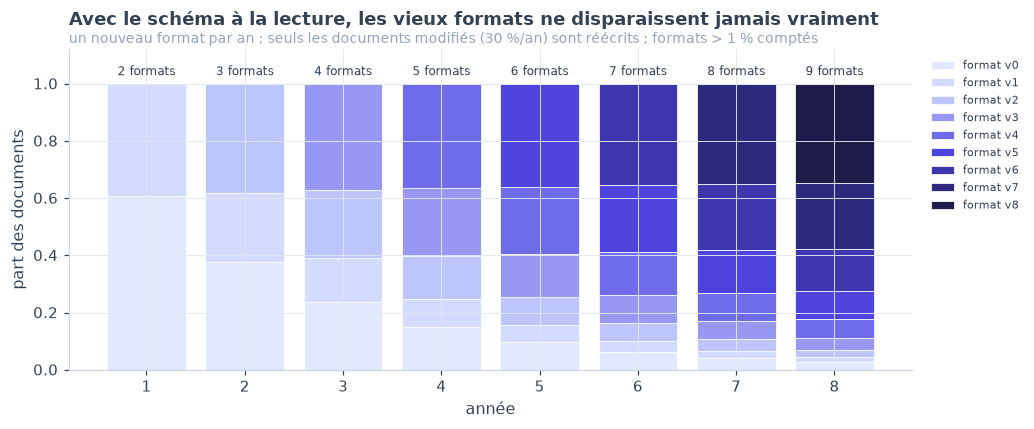

In [5]:
n_docs, years = 100_000, 8
version = np.zeros(n_docs, dtype=int)
hist = []
for y in range(1, years + 1):
    touched = rng.random(version.size) < 0.30
    version[touched] = y
    version = np.concatenate([version, np.full(15_000, y)])
    hist.append(np.bincount(version, minlength=years + 1))
hist = np.array(hist)

fig, ax = plt.subplots(figsize=(9.5, 4))
bottom = np.zeros(years)
cmap = plt.get_cmap("ddia_seq")
for v in range(years + 1):
    frac = hist[:, v] / hist.sum(axis=1)
    ax.bar(np.arange(1, years + 1), frac, bottom=bottom, color=cmap(0.15 + 0.85 * v / years),
           edgecolor="white", lw=0.5, label=f"format v{v}")
    bottom += frac
for y in range(years):
    n_formats = (hist[y] > 0.01 * hist[y].sum()).sum()
    ax.text(y + 1, 1.03, f"{n_formats} formats", ha="center", fontsize=8, color=SLATE)
ax.set_xlabel("année"); ax.set_ylabel("part des documents"); ax.set_ylim(0, 1.12)
ax.set_title("Avec le schéma à la lecture, les vieux formats ne disparaissent jamais vraiment")
subtitle(ax, "un nouveau format par an ; seuls les documents modifiés (30 %/an) sont réécrits ; formats > 1 % comptés")
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1.0)); plt.tight_layout(); plt.show()

Après huit ans, les neuf formats successifs pèsent encore chacun plus de 1 % des
documents : le code de lecture doit tous les comprendre. Le schéma à l'écriture concentre ce coût dans la migration ; le schéma à
la lecture le dilue dans tout le code, pour toujours.

**Quand le schéma à la lecture l'emporte-t-il ?** Quand les données sont
**hétérogènes** : de nombreux types d'objets qu'il serait absurde de ranger chacun dans
sa table, ou une structure dictée par des **systèmes externes** qui peuvent la changer à
tout moment. Exemple : des événements reçus de trois fournisseurs de paiement.

In [6]:
fournisseurs = {
    "A": lambda i: {"id": i, "amount": 10.0, "currency": "EUR", "status": "ok"},
    "B": lambda i: {"txn": i, "amount_cents": 1000, "meta": {"country": "FR"}, "state": "SETTLED"},
    "C": lambda i: {"id": i, "value": {"amount": "10.00", "ccy": "EUR"}, "events": ["created", "paid"],
                    **({"refund": True} if i % 7 == 0 else {})},
}
evts = [fournisseurs[f](i) for i in range(3000) for f in "ABC" if rng.random() < 0.6]
formes = Counter(tuple(sorted(e)) for e in evts)
pd.DataFrame({"ensemble de clés": [", ".join(k) for k in formes], "documents": list(formes.values())})

,ensemble de clés,documents
0,"amount, currency, id, status",1830
1,"amount_cents, meta, state, txn",1845
2,"events, id, refund, value",243
3,"events, id, value",1507


Quatre « formes » différentes coexistent (le fournisseur C ajoute un champ `refund`
certains jours) : un schéma relationnel strict demanderait une table par forme, et une
migration à chaque caprice d'un fournisseur. Ici, des documents sans schéma sont plus
naturels. Mais quand tous les enregistrements ont la même structure, un schéma est un
excellent moyen de la **documenter** et de la **faire respecter**. Nous reviendrons sur
l'évolution des schémas au chapitre 5.

> **À retenir.** « Sans schéma » signifie « schéma implicite, vérifié à la lecture ». Le
> schéma à l'écriture paie le changement de format en une migration (rapide pour
> ajouter une colonne, lente pour réécrire les lignes) ; le schéma à la lecture le paie
> dans tout le code lecteur, indéfiniment. Il gagne pour les données hétérogènes.

## 3. Déclaratif contre impératif (section *Terminology: Declarative Query Languages*)

SQL, comme Cypher, SPARQL et Datalog que nous verrons ensuite, est **déclaratif** : on
décrit **ce que** l'on veut (quelles conditions, quels tris, quels regroupements), pas
**comment** l'obtenir. Un langage de programmation comme Python est **impératif** : on
écrit l'algorithme, opération par opération. Exemple du livre : la liste des requins
parmi des observations d'animaux marins.

In [7]:
obs = dm.make_observations(200_000, seed=1)

def sharks_imperative(observations):
    result = []
    for o in observations:                     # l'ordre de parcours est imposé
        if o["family"] == "Sharks":
            result.append(o)
    return result

oc = sqlite3.connect(":memory:")
oc.execute("CREATE TABLE observations (id INTEGER PRIMARY KEY, ts TEXT, family TEXT, species TEXT, num_animals INTEGER)")
oc.executemany("INSERT INTO observations VALUES (?, ?, ?, ?, ?)",
               [(o["_id"], o["observationTimestamp"], o["family"], o["species"], o["numAnimals"]) for o in obs])
SQL_SHARKS = "SELECT * FROM observations WHERE family = 'Sharks'"
assert len(sharks_imperative(obs)) == len(oc.execute(SQL_SHARKS).fetchall())
print(f"{len(sharks_imperative(obs)):,} observations de requins sur {len(obs):,}".replace(",", " "))

59 838 observations de requins sur 200 000


Le déclaratif est plus concis, mais son vrai atout est ailleurs : il **cache
l'implémentation**, ce qui laisse la base libre de l'améliorer sans toucher aux requêtes.
Créons un index sur `family` : la requête SQL, inchangée, change de plan d'exécution.
Le code impératif, lui, ne profiterait d'un index que si on le réécrivait.

In [8]:
def sql_time(sql, n=20):
    t0 = time.perf_counter()
    for _ in range(n):
        oc.execute(sql).fetchall()
    return (time.perf_counter() - t0) / n * 1e3

SQL_RARE = ("SELECT COUNT(*), SUM(num_animals) FROM observations "
            "WHERE family = 'Rays' AND species = 'Raie manta' AND num_animals >= 8")
avant = (" | ".join(r[-1] for r in oc.execute("EXPLAIN QUERY PLAN " + SQL_RARE)), sql_time(SQL_RARE))
oc.execute("CREATE INDEX obs_fsn ON observations (family, species, num_animals)")
apres = (" | ".join(r[-1] for r in oc.execute("EXPLAIN QUERY PLAN " + SQL_RARE)), sql_time(SQL_RARE))
pd.DataFrame({"index": ["aucun", "(family, species, num_animals)"], "plan choisi par SQLite": [avant[0], apres[0]],
              "ms par requête": [avant[1], apres[1]]})

,index,plan choisi par SQLite,ms par requête
0,aucun,SCAN observations,5.930
1,"(family, species, num_animals)",SEARCH observations USING COVERING INDEX obs_fsn (family=? AND species=? AND num_anima...,0.011


Même texte de requête, plan différent : un parcours complet de la table devient une
recherche dans un index **couvrant** (il contient toutes les colonnes utiles), et la
requête, qui ne concerne qu'une centaine de lignes, devient des dizaines de fois plus
rapide.

Le second atout est le **parallélisme**. Une requête déclarative ne fixe aucun ordre :
le moteur peut découper les données entre plusieurs cœurs ou machines et combiner les
résultats partiels, à condition que l'agrégat s'y prête (une somme se calcule par
morceaux puis s'additionne). Le code impératif ci-dessus, avec son `append` dans une
liste partagée, impose un ordre séquentiel ; le paralléliser serait un travail à part
entière. Montrons le découpage qu'un moteur pourrait faire.

In [9]:
chunks = np.array_split(np.arange(len(obs)), 4)
partiels = [sum(obs[i]["numAnimals"] for i in idx if obs[i]["family"] == "Sharks") for idx in chunks]
total = sum(o["numAnimals"] for o in obs if o["family"] == "Sharks")
print("sommes partielles par morceau :", partiels, "-> total", sum(partiels), "=", total)

sommes partielles par morceau : [33910, 33335, 33408, 32927] -> total 133580 = 133580


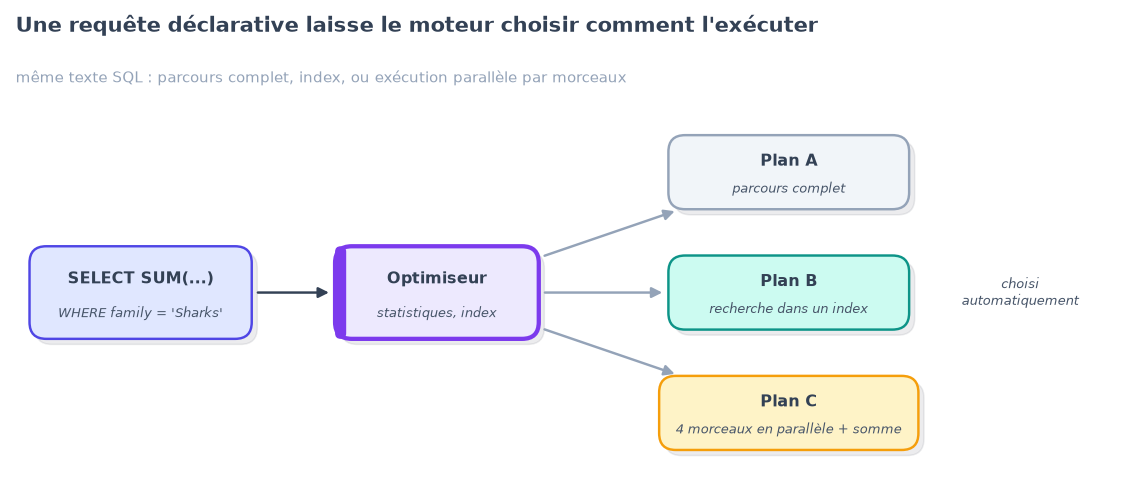

In [10]:
d = Diagram(12, 4.2, title="Une requête déclarative laisse le moteur choisir comment l'exécuter",
            subtitle="même texte SQL : parcours complet, index, ou exécution parallèle par morceaux")
d.box("q", 1.4, 2.1, "SELECT SUM(...)", sub="WHERE family = 'Sharks'", color=INDIGO, w=2.4, h=1.0)
d.box("opt", 4.6, 2.1, "Optimiseur", sub="statistiques, index", color=VIOLET, kind="model", w=2.2, h=1.0)
d.box("p1", 8.4, 3.4, "Plan A", sub="parcours complet", color=GRAY, w=2.6, h=0.8)
d.box("p2", 8.4, 2.1, "Plan B", sub="recherche dans un index", color=TEAL, w=2.6, h=0.8)
d.box("p3", 8.4, 0.8, "Plan C", sub="4 morceaux en parallèle + somme", color=AMBER, w=2.8, h=0.8)
d.arrow("q", "opt")
for p in ["p1", "p2", "p3"]:
    d.arrow("opt", p, color=GRAY)
d.note(10.9, 2.1, "choisi\nautomatiquement", fontsize=8.5)
d.show()

> **À retenir.** Un langage déclaratif décrit le résultat voulu, pas l'algorithme. Il est
> plus concis et surtout il laisse l'optimiseur choisir les index, l'ordre des jointures
> et le parallélisme, et en changer sans qu'on réécrive les requêtes.

## 4. Le pipeline d'agrégation, un langage de requête pour documents (section *Query languages for documents*)

Les langages de requête des bases documents sont plus variés que SQL : certaines bases
n'offrent que l'accès par clé primaire, d'autres des index secondaires sur des valeurs
imbriquées, d'autres de vrais langages. Les bases XML ont XQuery et XPath ; JSON a ses
équivalents de XPath (JSON Pointer, JSONPath) ; MongoDB a son **pipeline d'agrégation**.

Reprenons l'exemple de la biologiste marine : le nombre de requins observés chaque mois.
En SQL (dialecte PostgreSQL dans le livre, SQLite ici) :

In [11]:
SQL_MOIS = """SELECT substr(ts, 1, 7) AS mois, SUM(num_animals) AS total
                FROM observations WHERE family = 'Sharks' GROUP BY mois ORDER BY mois"""
sql_res = oc.execute(SQL_MOIS).fetchall()
sql_res[:3]

[('2017-01', 5637), ('2017-02', 5084), ('2017-03', 5433)]

Le même calcul en pipeline d'agrégation, exécuté par notre mini-moteur `dm.aggregate`
(qui implémente `$match`, `$group`, `$sort`, `$unwind`, `$lookup`, `$project`...) :

In [12]:
PIPE = [
    {"$match": {"family": "Sharks"}},
    {"$group": {"_id": {"year": {"$year": "$observationTimestamp"},
                        "month": {"$month": "$observationTimestamp"}},
                "totalAnimals": {"$sum": "$numAnimals"}}},
    {"$sort": {"_id.year": 1, "_id.month": 1}},
]
etapes = {}
pipe_res = dm.aggregate(obs, PIPE, stats=etapes)
assert [(f"{r['_id']['year']}-{r['_id']['month']:02d}", r["totalAnimals"]) for r in pipe_res] == sql_res
pipe_res[:3]

[{'_id': {'year': 2017, 'month': 1}, 'totalAnimals': 5637},
 {'_id': {'year': 2017, 'month': 2}, 'totalAnimals': 5084},
 {'_id': {'year': 2017, 'month': 3}, 'totalAnimals': 5433}]

Les deux langages ont la même expressivité sur cet exemple (le pipeline équivaut à peu
près à un sous-ensemble de SQL) ; l'un s'écrit comme une phrase anglaise, l'autre comme
du JSON. Un pipeline se lit comme une **chaîne d'étapes** : chacune reçoit le flot de
documents de la précédente. Visualisons le volume qui traverse chaque étape, sur un
pipeline plus riche : les employeurs les plus fréquents dans nos CV.

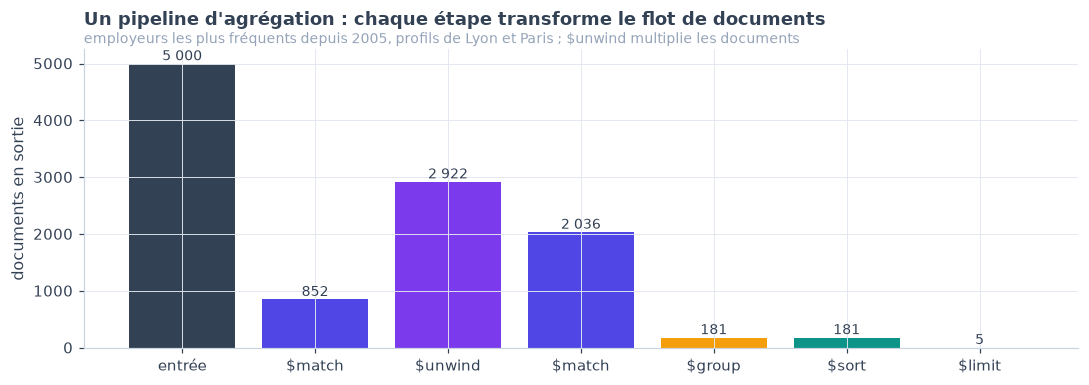

,_id,postes
0,Terracorp,429
1,Atlassys,193
2,Cieltech,141
3,Briotech,92
4,Cloudmetrics,82


In [13]:
profiles = dm.make_profiles(5000, seed=0)
PIPE2 = [
    {"$match": {"region_id": {"$in": ["fr:69", "fr:75"]}}},
    {"$unwind": "$positions"},
    {"$match": {"positions.start": {"$gte": 2005}}},
    {"$group": {"_id": "$positions.organization", "postes": {"$sum": 1}}},
    {"$sort": {"postes": -1}},
    {"$limit": 5},
]
st2 = {}
top = dm.aggregate(profiles, PIPE2, stats=st2)
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = ["entrée"] + [k.split(":")[1] for k in st2]
vals = [len(profiles)] + list(st2.values())
ax.bar(range(len(vals)), vals, color=[SLATE, INDIGO, VIOLET, INDIGO, AMBER, TEAL, TEAL])
ax.set_xticks(range(len(vals)), labels)
for i, v in enumerate(vals):
    ax.text(i, v + 60, fmt(v), ha="center", fontsize=9, color=SLATE)
ax.set_ylabel("documents en sortie")
ax.set_title("Un pipeline d'agrégation : chaque étape transforme le flot de documents")
subtitle(ax, "employeurs les plus fréquents depuis 2005, profils de Lyon et Paris ; $unwind multiplie les documents")
plt.tight_layout(); plt.show()
pd.DataFrame(top)

`$unwind` **déplie** chaque profil en autant de documents qu'il a de postes (le flot
grossit), puis `$group` les agrège par employeur. C'est exactement ce que ferait une
jointure entre `users` et `positions` suivie d'un `GROUP BY`.

> **À retenir.** Le pipeline d'agrégation de MongoDB est un langage déclaratif à syntaxe
> JSON, d'expressivité comparable à un sous-ensemble de SQL : filtrer, déplier,
> regrouper, trier, joindre (`$lookup`). Le choix entre les deux syntaxes est en partie
> affaire de goût.

## 5. La convergence des modèles (section *Convergence of document and relational databases*)

Partis de philosophies opposées, les deux mondes se sont rapprochés. Les bases
relationnelles ont ajouté des **types JSON**, des opérateurs pour les interroger et la
possibilité d'**indexer des propriétés internes** aux documents ; des bases documents ont
ajouté jointures, index secondaires et langages déclaratifs. SQLite illustre bien le
premier mouvement : on y range des documents JSON dans une colonne texte, et on peut
créer un index sur une **expression** qui extrait un champ.

In [14]:
dc = sqlite3.connect(":memory:")
dm.create_documents(dc, dm.make_profiles(50_000, seed=3))
Q = "SELECT COUNT(*) FROM profiles WHERE doc ->> '$.region_id' = 'ca:qc'"
def best_time(sql, n=5):
    best = np.inf
    for _ in range(n):
        t0 = time.perf_counter(); dc.execute(sql).fetchone(); best = min(best, time.perf_counter() - t0)
    return best

t_sans = best_time(Q)
plan_sans = " | ".join(r[-1] for r in dc.execute("EXPLAIN QUERY PLAN " + Q))
dc.execute("CREATE INDEX profiles_region ON profiles (doc ->> '$.region_id')")
t_avec = best_time(Q)
plan_avec = " | ".join(r[-1] for r in dc.execute("EXPLAIN QUERY PLAN " + Q))
pd.DataFrame({"index sur doc ->> '$.region_id'": ["non", "oui"], "plan": [plan_sans, plan_avec],
              "ms": [t_sans * 1e3, t_avec * 1e3]})

,index sur doc ->> '$.region_id',plan,ms
0,non,SCAN profiles,52.765
1,oui,SEARCH profiles USING INDEX profiles_region (<expr>=?),0.103


Sans index, chaque document est analysé ; avec l'index sur l'expression, la base cherche
directement les profils québécois, comme pour une colonne ordinaire. Les deux modèles se
combinent alors dans une même table : des **colonnes relationnelles** pour ce qui est
structuré et référencé, une **colonne JSON** pour ce qui est variable. Le livre y voit
une bonne nouvelle : la plupart des applications ont besoin des deux, et les **hybrides
relationnel-document** sont une combinaison puissante.

L'idée n'est d'ailleurs pas neuve : la description originale du modèle relationnel par
Codd autorisait déjà des valeurs qui ne sont pas des nombres ou des chaînes mais des
**relations imbriquées** (les *nonsimple domains*), donc des arbres arbitraires, un peu
comme le JSON ajouté à SQL plus de trente ans plus tard.

> **À retenir.** Bases relationnelles et documents convergent : JSON indexable côté SQL,
> jointures et langages déclaratifs côté documents. Combiner colonnes structurées et
> colonne JSON donne le meilleur des deux.

## 6. Les listes réordonnables et l'indexation fractionnaire (section *When to Use Which Model*)

Dernier argument en faveur des documents : les listes **dont l'utilisateur choisit
l'ordre** (une liste de tâches qu'on réorganise par glisser-déposer). Dans un document,
il suffit de ranger les éléments (ou leurs identifiants) dans un tableau JSON. En
relationnel, une table n'a pas d'ordre, et il n'existe pas de façon standard de
représenter une liste réordonnable. Le livre cite trois astuces :

- une colonne **entière** `position` : insérer au milieu oblige à **renuméroter** les
  éléments suivants ;
- une **liste chaînée** d'identifiants (chaque ligne pointe vers la suivante) : insertion
  en O(1) mais lecture ordonnée par une requête récursive ;
- l'**indexation fractionnaire** : la clé de tri est une chaîne, et pour insérer entre
  `a` et `b` on fabrique une clé strictement comprise entre les deux (comme 0,5 entre 0
  et 1, puis 0,25...). Une seule ligne écrite par insertion.

Notre implémentation `key_between` travaille en base 36 ; comparons le nombre de lignes
écrites par insertion pour une liste qui grandit par insertions à des positions
aléatoires.

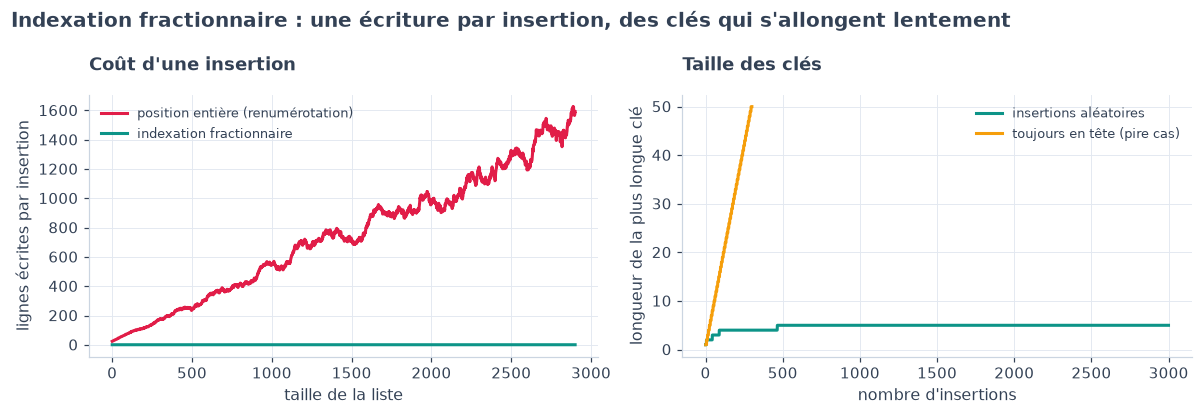

In [15]:
from ddia.datamodels_ed2 import key_between

n_ins = 3000
pos_rng = np.random.default_rng(4)
keys, int_list, maj_int, longueur = [], [], [], []
for i in range(n_ins):
    j = int(pos_rng.integers(0, len(keys) + 1))
    keys.insert(j, key_between(keys[j - 1] if j > 0 else None, keys[j] if j < len(keys) else None))
    maj_int.append(len(int_list) - j + 1)           # position entière : renuméroter j..fin, puis insérer
    int_list.insert(j, i)
    longueur.append(max(map(len, keys)))
assert keys == sorted(keys)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
win = 100
ax.plot(np.convolve(maj_int, np.ones(win) / win, "valid"), color=ROSE, label="position entière (renumérotation)")
ax.plot(np.ones(n_ins - win + 1), color=TEAL, lw=2, label="indexation fractionnaire")
ax.set_xlabel("taille de la liste"); ax.set_ylabel("lignes écrites par insertion")
ax.set_title("Coût d'une insertion"); ax.legend(fontsize=8.5)
ax = axes[1]
prep = []
for i in range(300):                                 # pire cas : toujours insérer en tête
    prep.insert(0, key_between(None, prep[0] if prep else None))
ax.plot(longueur, color=TEAL, label="insertions aléatoires")
ax.plot(np.arange(1, 301), [len(k) for k in prep[::-1]], color=AMBER, label="toujours en tête (pire cas)")
ax.set_xlabel("nombre d'insertions"); ax.set_ylabel("longueur de la plus longue clé")
ax.set_title("Taille des clés"); ax.legend(fontsize=8.5)
finish(fig, "Indexation fractionnaire : une écriture par insertion, des clés qui s'allongent lentement")

Avec des positions entières, une insertion aléatoire réécrit en moyenne la moitié de la
liste ; avec l'indexation fractionnaire, une seule ligne, et les clés restent très
courtes (quelques caractères pour 3 000 éléments) tant que les insertions sont
dispersées. Le pire cas, toujours insérer en tête, allonge la clé d'environ un caractère
toutes les six insertions : les implémentations réelles ajoutent une partie « entière »
à longueur variable pour l'éviter. Cette technique est très utilisée par les
applications collaboratives, où plusieurs personnes réordonnent la même liste.

> **À retenir.** Un tableau JSON représente naturellement une liste ordonnée ; en
> relationnel, il faut une astuce : renumérotation coûteuse, liste chaînée, ou
> indexation fractionnaire (une écriture par insertion, clés courtes en pratique).

## Synthèse

- Arbre lu d'un bloc : **document**. Relations plusieurs-à-plusieurs : **relationnel**
  (ou graphe). Un élément imbriqué n'a pas d'adresse stable sans identifiant.
- « Sans schéma » veut dire **schéma à la lecture** : souple, adapté aux données
  hétérogènes, mais chaque lecteur doit gérer tous les formats passés. Le **schéma à
  l'écriture** concentre le coût dans des migrations (ajouter une colonne est rapide,
  réécrire les lignes est lent).
- Les langages **déclaratifs** (SQL, pipeline d'agrégation) laissent le moteur
  choisir index, ordre et parallélisme.
- Les deux mondes **convergent** : JSON indexable dans les bases SQL, jointures dans les
  bases documents. Les listes réordonnables restent un point fort des documents, que l'indexation fractionnaire compense en relationnel.

Le chapitre 5 reviendra sur l'évolution des schémas et la compatibilité
entre versions.
Le cours 4 passe au troisième grand modèle : les **graphes**.